# RAG vs GraphRAG — Workload Characterization Plots

Publication-quality figures from `workload.py` JSON results.

**Usage:** Set `RESULT_JSON` below to the path of the workload result you want to plot.

In [1]:
# ── Configuration ────────────────────────────────────────────────────
# Point this to the JSON file produced by workload.py
RESULT_JSON = "workload_results/RoG-cwq_gemma-2-2b_N32_B128_b1_workload.json"
# ─────────────────────────────────────────────────────────────────────

In [2]:
import json
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from pathlib import Path

# ── Paper style ──────────────────────────────────────────────────────
plt.rcParams.update({
    "figure.dpi":        150,
    "savefig.dpi":       300,
    "font.size":         9,
    "axes.titlesize":    10,
    "axes.labelsize":    9,
    "xtick.labelsize":   8,
    "ytick.labelsize":   8,
    "legend.fontsize":   8,
    "figure.figsize":    (7, 3.5),
    "axes.grid":         True,
    "grid.alpha":        0.3,
    "axes.spines.top":   False,
    "axes.spines.right": False,
})

# ── Load data ────────────────────────────────────────────────────────
with open(RESULT_JSON) as f:
    data = json.load(f)

CONFIGS  = ["rag", "rag_kv", "graphrag", "graphrag_kv"]
LABELS   = ["RAG\n(KV=OFF)", "RAG\n(KV=ON)", "GraphRAG\n(KV=OFF)", "GraphRAG\n(KV=ON)"]
COLORS   = ["#4878cf", "#6ab0e2", "#e24a33", "#f5a275"]
HATCHES  = ["", "//", "", "//"]

configs = [c for c in CONFIGS if c in data]
labels  = [LABELS[CONFIGS.index(c)] for c in configs]
colors  = [COLORS[CONFIGS.index(c)] for c in configs]
hatches = [HATCHES[CONFIGS.index(c)] for c in configs]

def val(config, *keys, stat="mean"):
    """Navigate nested JSON: val('rag', 'generation', 'ttft_ms') -> mean."""
    v = data[config]
    for k in keys:
        v = v[k]
    if isinstance(v, dict) and stat in v:
        return v[stat]
    return v

model  = val(configs[0], "model")
n_samp = val(configs[0], "n_samples")
gpu    = val(configs[0], "hw", "gpu")
print(f"Model: {model}  |  N={n_samp}  |  GPU: {gpu}")

Model: google/gemma-2-2b  |  N=32  |  GPU: NVIDIA A100 80GB PCIe


In [3]:
# ── Helper: grouped bar chart ────────────────────────────────────────
def bar_chart(values, ylabel, title, ax=None, fmt=".0f", logy=False):
    if ax is None:
        _, ax = plt.subplots(figsize=(5, 3.2))
    x = np.arange(len(configs))
    bars = ax.bar(x, values, color=colors, edgecolor="black", linewidth=0.5,
                  width=0.6)
    for bar, h in zip(bars, hatches):
        bar.set_hatch(h)
    for i, v in enumerate(values):
        ax.text(i, v * 1.02, f"{v:{fmt}}", ha="center", va="bottom", fontsize=7)
    ax.set_xticks(x)
    ax.set_xticklabels(labels)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    if logy:
        ax.set_yscale("log")
    ax.set_ylim(0, max(values) * 1.18)
    return ax

## 1 — Answer Quality

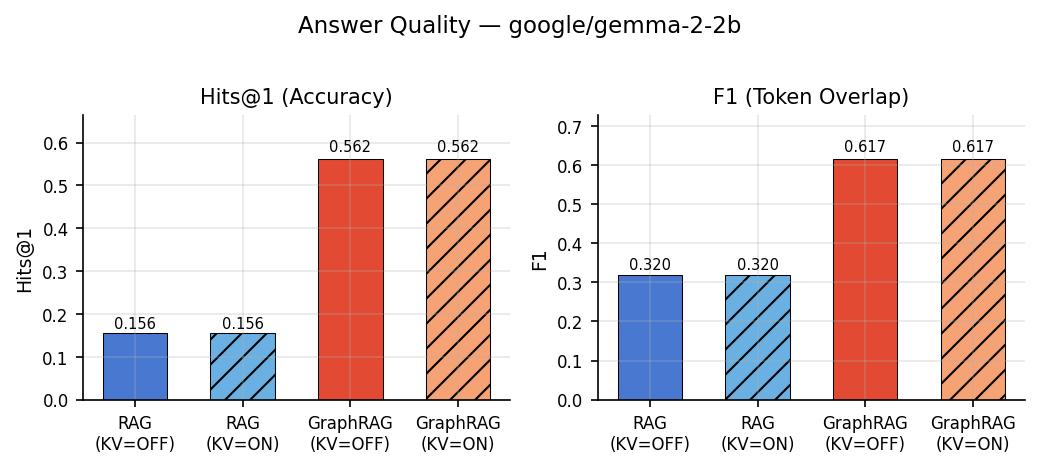

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(7, 3))
bar_chart([val(c, "quality", "hits_at_1") for c in configs],
          "Hits@1", "Hits@1 (Accuracy)", ax=ax1, fmt=".3f")
bar_chart([val(c, "quality", "f1") for c in configs],
          "F1", "F1 (Token Overlap)", ax=ax2, fmt=".3f")
fig.suptitle(f"Answer Quality — {model}", fontsize=11, y=1.02)
fig.tight_layout()
plt.show()

## 2 — Latency Breakdown (Stacked)

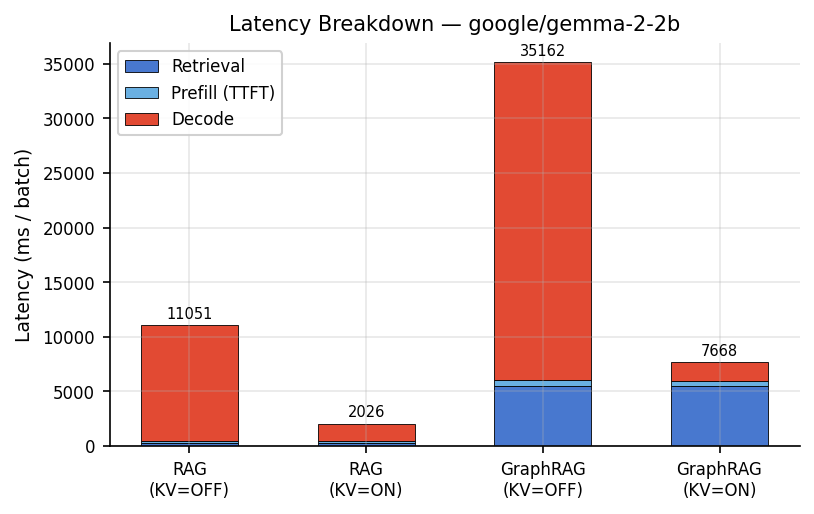

In [5]:
retr   = [val(c, "retrieval", "lat_ms") for c in configs]
ttft   = [val(c, "generation", "ttft_ms") for c in configs]
decode = [val(c, "generation", "decode_ms") for c in configs]

fig, ax = plt.subplots(figsize=(5.5, 3.5))
x = np.arange(len(configs))
w = 0.55

b1 = ax.bar(x, retr,   w, label="Retrieval",  color="#4878cf", edgecolor="black", linewidth=0.4)
b2 = ax.bar(x, ttft,   w, bottom=retr, label="Prefill (TTFT)", color="#6ab0e2", edgecolor="black", linewidth=0.4)
bot2 = [r + t for r, t in zip(retr, ttft)]
b3 = ax.bar(x, decode, w, bottom=bot2, label="Decode", color="#e24a33", edgecolor="black", linewidth=0.4)

e2e = [r + t + d for r, t, d in zip(retr, ttft, decode)]
for i, v in enumerate(e2e):
    ax.text(i, v + max(e2e)*0.01, f"{v:.0f}", ha="center", va="bottom", fontsize=7)

ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylabel("Latency (ms / batch)")
ax.set_title(f"Latency Breakdown — {model}")
ax.legend(loc="upper left", framealpha=0.9)
fig.tight_layout()
plt.show()

## 3 — E2E Time Fraction (Pie / Stacked 100%)

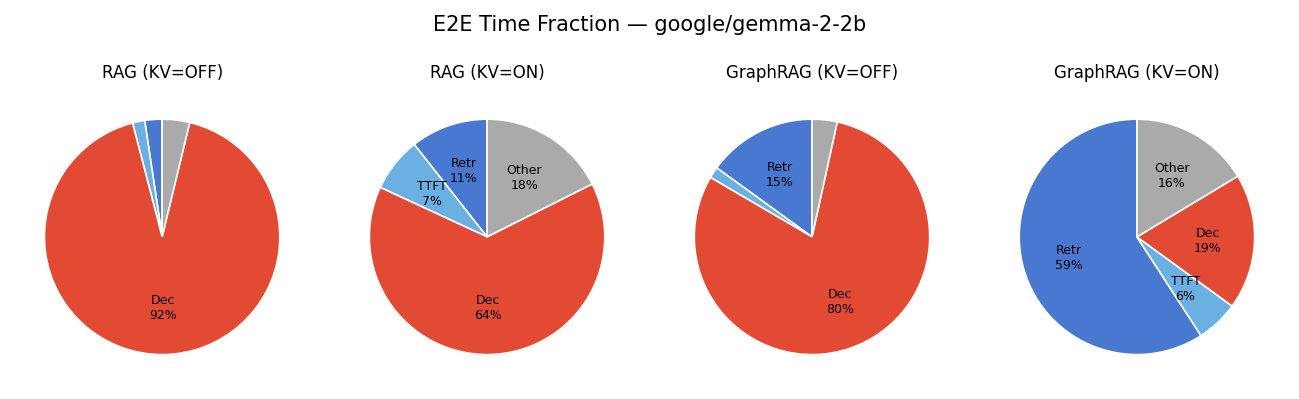

In [6]:
fig, axes = plt.subplots(1, len(configs), figsize=(2.2 * len(configs), 2.5))
if len(configs) == 1:
    axes = [axes]
pie_colors = ["#4878cf", "#6ab0e2", "#e24a33", "#aaaaaa"]

for ax, c, lbl in zip(axes, configs, labels):
    r = val(c, "retrieval", "lat_ms")
    t = val(c, "generation", "ttft_ms")
    d = val(c, "generation", "decode_ms")
    e = val(c, "e2e_ms")
    other = max(0, e - r - t - d)
    fracs = [r, t, d, other]
    total = sum(fracs)
    pcts  = [100 * v / total for v in fracs]
    wedges, texts = ax.pie(
        pcts, colors=pie_colors, startangle=90,
        wedgeprops={"edgecolor": "white", "linewidth": 0.8})
    # Label slices > 5%
    for w, p, name in zip(wedges, pcts, ["Retr", "TTFT", "Dec", "Other"]):
        if p > 5:
            ang = (w.theta2 + w.theta1) / 2
            xp = 0.6 * np.cos(np.radians(ang))
            yp = 0.6 * np.sin(np.radians(ang))
            ax.text(xp, yp, f"{name}\n{p:.0f}%", ha="center", va="center", fontsize=6)
    ax.set_title(lbl.replace('\n', ' '), fontsize=8)

fig.suptitle(f"E2E Time Fraction — {model}", fontsize=10, y=1.04)
fig.tight_layout()
plt.show()

## 4 — Throughput

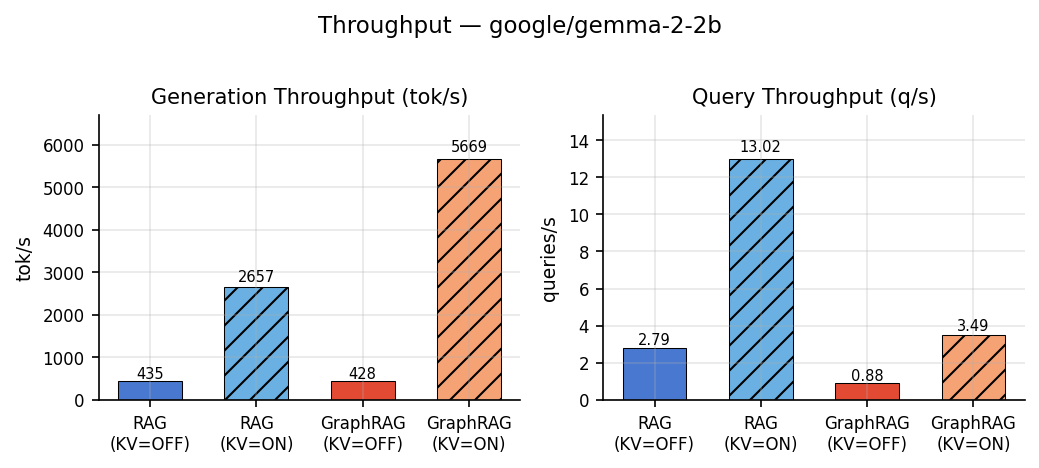

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(7, 3))
bar_chart([val(c, "generation", "tok_per_s") for c in configs],
          "tok/s", "Generation Throughput (tok/s)", ax=ax1)
qps = [val(c, "n_samples") / (val(c, "e2e_ms") / 1e3) for c in configs]
bar_chart(qps, "queries/s", "Query Throughput (q/s)", ax=ax2, fmt=".2f")
fig.suptitle(f"Throughput — {model}", fontsize=11, y=1.02)
fig.tight_layout()
plt.show()

## 5 — HBM Traffic Breakdown (Analytical)

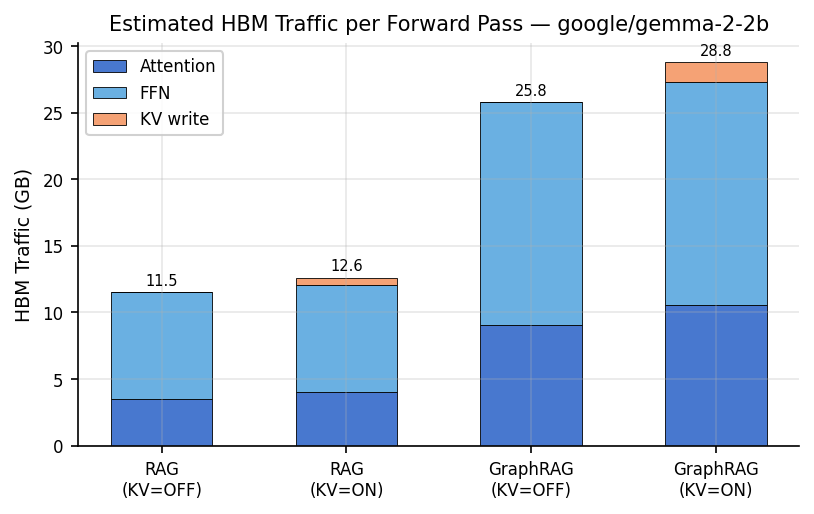

In [8]:
attn = [val(c, "analytic", "attn_GB") for c in configs]
ffn  = [val(c, "analytic", "ffn_GB")  for c in configs]
kv   = [val(c, "analytic", "kv_GB")   for c in configs]

fig, ax = plt.subplots(figsize=(5.5, 3.5))
x = np.arange(len(configs))
w = 0.55
ax.bar(x, attn, w, label="Attention", color="#4878cf", edgecolor="black", linewidth=0.4)
ax.bar(x, ffn,  w, bottom=attn, label="FFN", color="#6ab0e2", edgecolor="black", linewidth=0.4)
bot = [a + f for a, f in zip(attn, ffn)]
ax.bar(x, kv,   w, bottom=bot, label="KV write", color="#f5a275", edgecolor="black", linewidth=0.4)

totals = [a + f + k for a, f, k in zip(attn, ffn, kv)]
for i, v in enumerate(totals):
    ax.text(i, v + max(totals)*0.01, f"{v:.1f}", ha="center", va="bottom", fontsize=7)

ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylabel("HBM Traffic (GB)")
ax.set_title(f"Estimated HBM Traffic per Forward Pass — {model}")
ax.legend(loc="upper left", framealpha=0.9)
fig.tight_layout()
plt.show()

## 6 — Retrieval Statistics

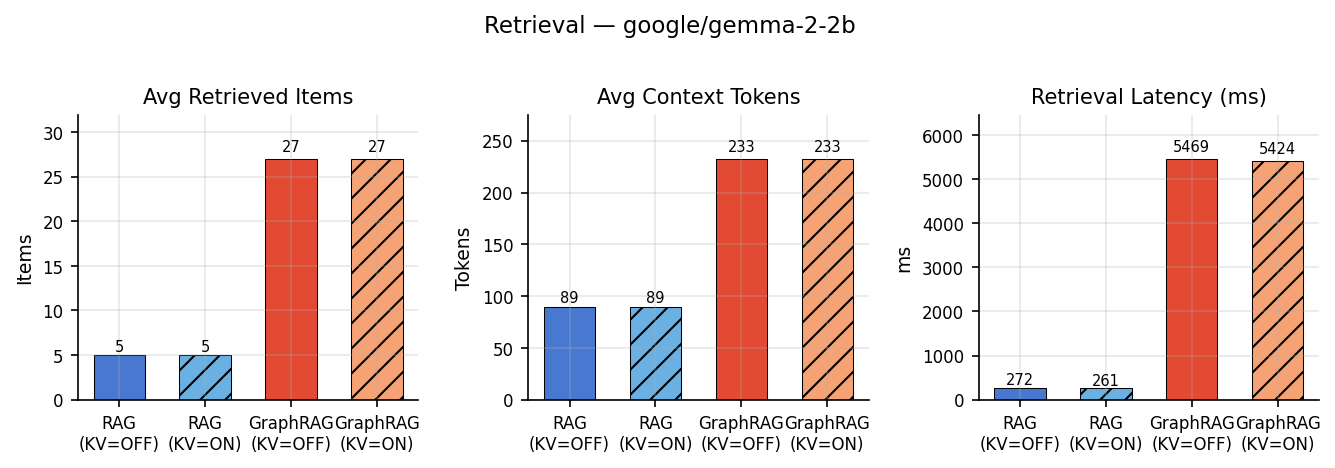

In [9]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(9, 3))

bar_chart([val(c, "retrieval", "avg_items") for c in configs],
          "Items", "Avg Retrieved Items", ax=ax1)

prompt_tok = [val(c, "retrieval", "avg_ctx_tok") or 0 for c in configs]
bar_chart(prompt_tok, "Tokens", "Avg Context Tokens", ax=ax2)

bar_chart([val(c, "retrieval", "lat_ms") for c in configs],
          "ms", "Retrieval Latency (ms)", ax=ax3)

fig.suptitle(f"Retrieval — {model}", fontsize=11, y=1.02)
fig.tight_layout()
plt.show()

## 7 — Speedup & Counterfactual

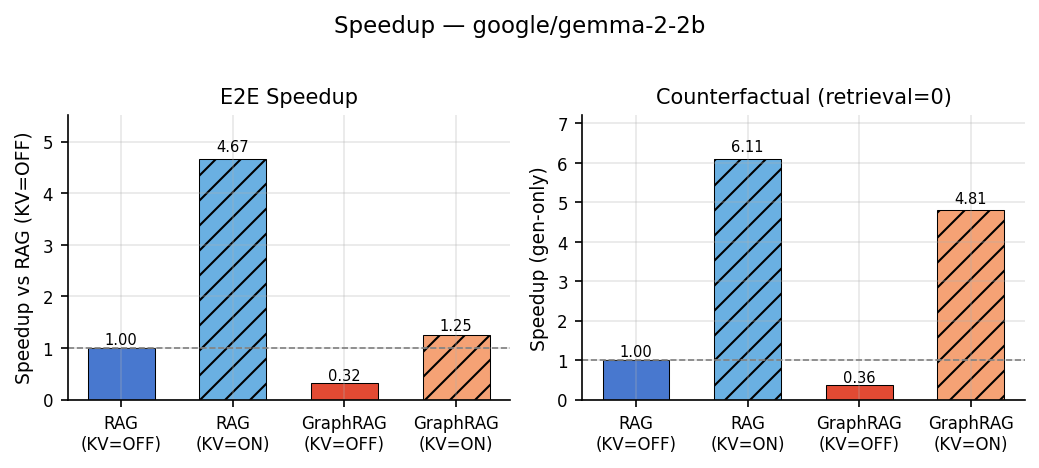

In [10]:
e2e_vals  = [val(c, "e2e_ms") for c in configs]
baseline  = e2e_vals[0]  # RAG KV=OFF
speedups  = [baseline / v for v in e2e_vals]

gen_only  = [val(c, "counterfactual", "gen_only_ms") for c in configs]
cf_speeds = [gen_only[0] / g if g > 0 else 0 for g in gen_only]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(7, 3))

bar_chart(speedups, "Speedup vs RAG (KV=OFF)",
          "E2E Speedup", ax=ax1, fmt=".2f")
ax1.axhline(1.0, color="gray", ls="--", lw=0.8)

bar_chart(cf_speeds, "Speedup (gen-only)",
          "Counterfactual (retrieval=0)", ax=ax2, fmt=".2f")
ax2.axhline(1.0, color="gray", ls="--", lw=0.8)

fig.suptitle(f"Speedup — {model}", fontsize=11, y=1.02)
fig.tight_layout()
plt.show()

## 8 — GPU Utilisation & Power

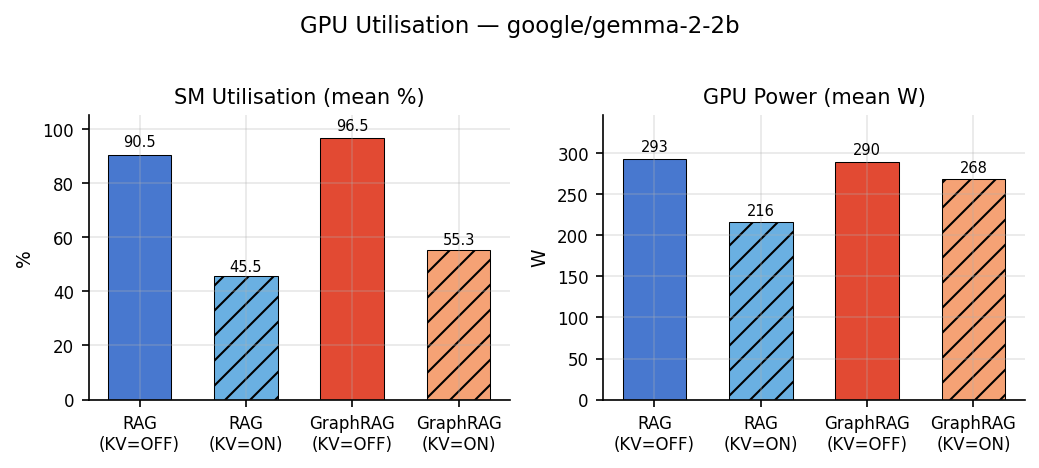

In [11]:
sm_pct  = [val(c, "hw", "sm_pct") for c in configs]
power_w = [val(c, "hw", "power_W") for c in configs]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(7, 3))
bar_chart(sm_pct,  "%", "SM Utilisation (mean %)", ax=ax1, fmt=".1f")
ax1.set_ylim(0, 105)
bar_chart(power_w, "W", "GPU Power (mean W)",      ax=ax2, fmt=".0f")
fig.suptitle(f"GPU Utilisation — {model}", fontsize=11, y=1.02)
fig.tight_layout()
plt.show()

## 9 — Path Enumeration (GraphRAG only)

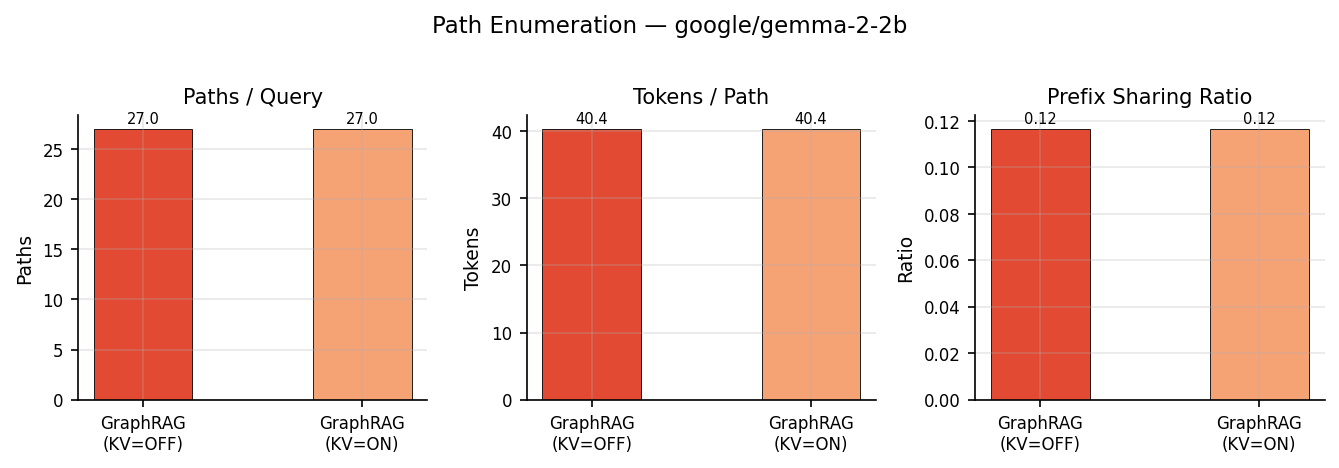

In [12]:
graph_cfgs = [c for c in configs if data[c].get("path_stats", {})]
if graph_cfgs:
    gl = [LABELS[CONFIGS.index(c)] for c in graph_cfgs]
    gc = [COLORS[CONFIGS.index(c)] for c in graph_cfgs]

    ppq    = [val(c, "path_stats", "paths_per_query") for c in graph_cfgs]
    tpp    = [val(c, "path_stats", "tokens_per_path") for c in graph_cfgs]
    prefix = [val(c, "path_stats", "prefix_sharing")  for c in graph_cfgs]

    fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(9, 3))
    x = np.arange(len(graph_cfgs))
    w = 0.45

    ax1.bar(x, ppq,    w, color=gc, edgecolor="black", linewidth=0.4)
    for i, v in enumerate(ppq):    ax1.text(i, v*1.02, f"{v:.1f}", ha="center", fontsize=7)
    ax1.set_xticks(x); ax1.set_xticklabels(gl); ax1.set_ylabel("Paths"); ax1.set_title("Paths / Query")

    ax2.bar(x, tpp,    w, color=gc, edgecolor="black", linewidth=0.4)
    for i, v in enumerate(tpp):    ax2.text(i, v*1.02, f"{v:.1f}", ha="center", fontsize=7)
    ax2.set_xticks(x); ax2.set_xticklabels(gl); ax2.set_ylabel("Tokens"); ax2.set_title("Tokens / Path")

    ax3.bar(x, prefix, w, color=gc, edgecolor="black", linewidth=0.4)
    for i, v in enumerate(prefix): ax3.text(i, v*1.02, f"{v:.2f}", ha="center", fontsize=7)
    ax3.set_xticks(x); ax3.set_xticklabels(gl); ax3.set_ylabel("Ratio"); ax3.set_title("Prefix Sharing Ratio")

    fig.suptitle(f"Path Enumeration — {model}", fontsize=11, y=1.02)
    fig.tight_layout()
    plt.show()
else:
    print("No GraphRAG path stats in this result file.")

## 10 — Summary Table

In [ ]:
from IPython.display import display, HTML

header_labels = [LABELS[CONFIGS.index(c)].replace('\n', ' ') for c in configs]
rows = [
    ("Hits@1",              "",      [f"{val(c,'quality','hits_at_1'):.3f}" for c in configs]),
    ("F1",                  "",      [f"{val(c,'quality','f1'):.3f}" for c in configs]),
    ("Retrieval (ms)",      "ms",    [f"{val(c,'retrieval','lat_ms'):.0f}" for c in configs]),
    ("TTFT / Prefill (ms)", "ms",    [f"{val(c,'generation','ttft_ms'):.0f}" for c in configs]),
    ("Decode (ms)",         "ms",    [f"{val(c,'generation','decode_ms'):.0f}" for c in configs]),
    ("E2E (ms)",            "ms",    [f"{val(c,'e2e_ms'):.0f}" for c in configs]),
    ("Gen tok/s",           "tok/s", [f"{val(c,'generation','tok_per_s'):.0f}" for c in configs]),
    ("Queries/s",           "q/s",   [f"{val(c,'n_samples')/(val(c,'e2e_ms')/1e3):.2f}" for c in configs]),
    ("HBM Traffic (GB)",    "GB",    [f"{val(c,'analytic','total_GB'):.1f}" for c in configs]),
    ("SM Util (%)",         "%",     [f"{val(c,'hw','sm_pct'):.1f}" for c in configs]),
    ("Power (W)",           "W",     [f"{val(c,'hw','power_W'):.0f}" for c in configs]),
    ("Speedup",             "x",     [f"{e2e_vals[0]/val(c,'e2e_ms'):.2f}" for c in configs]),
]

html = '<table style="border-collapse:collapse; font-size:9pt;">'
html += '<tr style="border-bottom:2px solid black;"><th style="text-align:left; padding:3px 8px;">Metric</th>'
for h in header_labels:
    html += f'<th style="text-align:right; padding:3px 8px;">{h}</th>'
html += '</tr>'
for name, unit, vals in rows:
    html += '<tr style="border-bottom:1px solid #ddd;">'
    html += f'<td style="text-align:left; padding:2px 8px;">{name}</td>'
    for v in vals:
        html += f'<td style="text-align:right; padding:2px 8px; font-family:monospace;">{v}</td>'
    html += '</tr>'
html += '</table>'
display(HTML(html))